In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp15: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
np.random.seed(15); tf.random.set_seed(15)
def gradient_trace(seq_len,activation):
    model=tf.keras.Sequential([tf.keras.layers.Input((seq_len,1)),tf.keras.layers.SimpleRNN(12,activation=activation,return_sequences=True),tf.keras.layers.Dense(1)])
    x=tf.random.normal((1,seq_len,1))
    with tf.GradientTape() as tape:
        tape.watch(x); states=model.layers[0](x); output=model.layers[1](states); loss=tf.reduce_mean(output[:,-1,:]**2)
    grad=tape.gradient(loss,states)
    return tf.norm(grad,axis=-1).numpy().ravel()
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
for j,L in enumerate([10,50,100]):
 for act in ["tanh","relu"]:
    g=gradient_trace(L,act); ax[j].plot(g,label=act)
 ax[j].set_title(f"Sequence length {L}"); ax[j].set_xlabel("Time step"); ax[j].set_ylabel("Gradient norm"); ax[j].set_yscale("log"); ax[j].legend(); ax[j].grid()
plt.tight_layout(); plt.show()
for L in [10,50,100]:
 print("Sequence length",L,"tanh first/last gradient:",np.round(gradient_trace(L,"tanh")[[0,-1]],8))

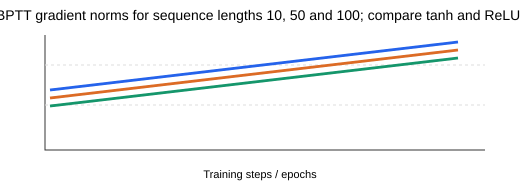

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.